# Heart Disease Risk Prediction (HDRPS)

Interpretable Logistic Regression system for binary heart disease prediction using `Dataset/heart.csv`.

### Imports

Importing the required libraries and set up the notebook environment for the analysis pipeline.

In [31]:
# Core imports
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42


### Load Dataset and Display first 5 rows

Loading the heart disease dataset and preview its structure to confirm the data is ready for analysis.

In [32]:
# Load dataset
DATA_PATH = 'Dataset/heart.csv'
df = pd.read_csv(DATA_PATH)

print('Shape:', df.shape)
display(df.head())
display(df.info())


Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


None

### Data Preprocessing

Checking missing values and target distribution to validate data quality before modelling.

Missing values by column:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


Target distribution:


,count,proportion
target,,
0,499,0.487
1,526,0.513


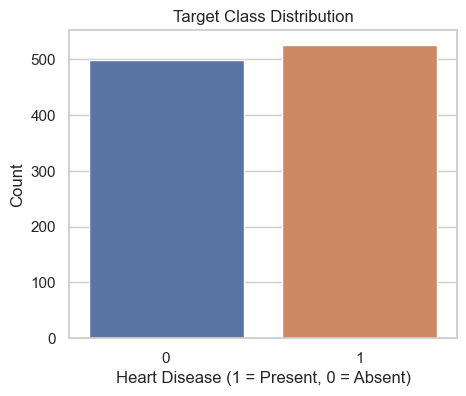

In [33]:
# Data quality checks
print('Missing values by column:')
display(df.isna().sum())

print('\nTarget distribution:')
target_counts = df['target'].value_counts().sort_index()
target_props = df['target'].value_counts(normalize=True).sort_index().round(3)
display(pd.DataFrame({'count': target_counts, 'proportion': target_props}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='target', data=df, ax=ax)
ax.set_title('Target Class Distribution')
ax.set_xlabel('Heart Disease (1 = Present, 0 = Absent)')
ax.set_ylabel('Count')
plt.show()


### Descriptive Statistics

Descriptive statistics and correlation analysis to identify key exploratory patterns in the dataset.

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


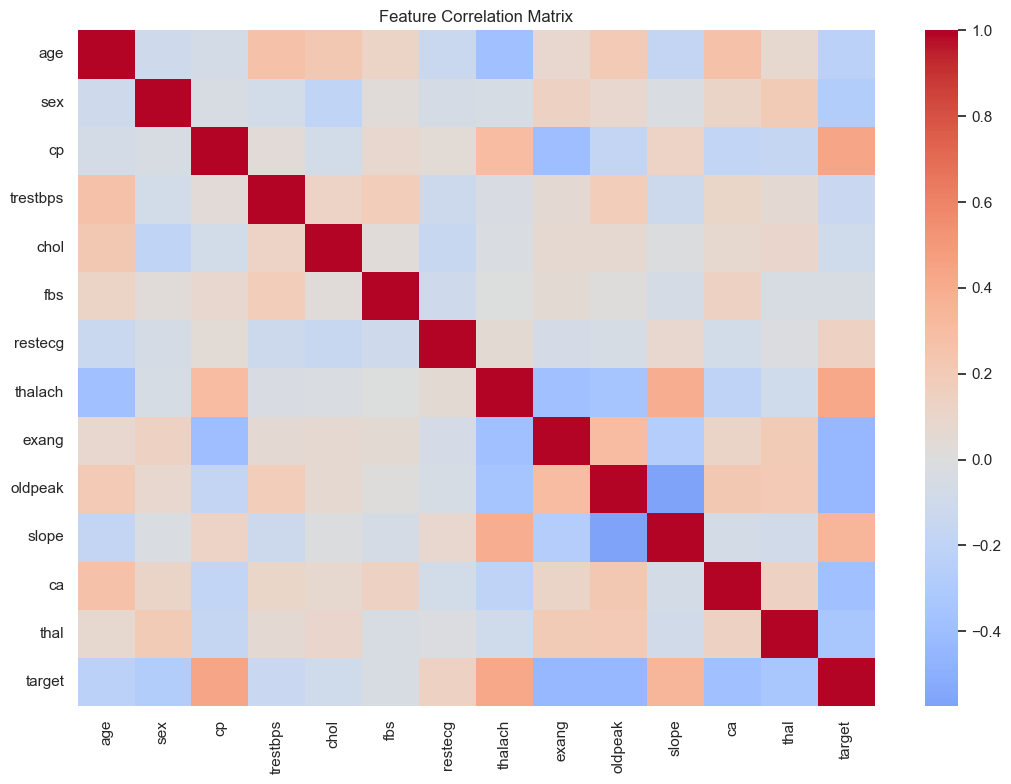

,corr_with_target
oldpeak,-0.438441
exang,-0.438029
cp,0.434854
thalach,0.422895
ca,-0.382085
slope,0.345512
thal,-0.337838
sex,-0.279501
age,-0.229324
trestbps,-0.138772


In [34]:
# Exploratory analysis: summary statistics and correlations
display(df.describe().T)

corr = df.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

target_corr = corr['target'].drop('target').sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.to_frame('corr_with_target'))


### Dataset Split

Define predictors and target, then create a stratified train-test split for robust model evaluation.

In [35]:
# Prepare features and target
feature_cols = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal'
]
X = df[feature_cols].copy()
y = df['target'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Train target proportion:', y_train.mean().round(3))
print('Test target proportion:', y_test.mean().round(3))


Train shape: (820, 13) Test shape: (205, 13)
Train target proportion: 0.513
Test target proportion: 0.512


### Model Training

The Logistic Regression pipeline, run cross-validation, and fit the final model on training data.

In [36]:
# Logistic Regression pipeline (scaling + model)
log_reg_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
])

# Cross-validation on training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(log_reg_pipe, X_train, y_train, cv=cv, scoring='roc_auc')
cv_f1 = cross_val_score(log_reg_pipe, X_train, y_train, cv=cv, scoring='f1')

print(f'CV ROC-AUC: {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}')
print(f'CV F1-score: {cv_f1.mean():.3f} +/- {cv_f1.std():.3f}')

# Fit final model
log_reg_pipe.fit(X_train, y_train)


CV ROC-AUC: 0.916 +/- 0.015
CV F1-score: 0.850 +/- 0.018


Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

### Model Evaluation

Evaluating model performance on unseen test data using classification metrics and confusion-matrix diagnostics.

,Logistic Regression
accuracy,0.809756
precision,0.761905
recall,0.914286
f1_score,0.831169
roc_auc,0.930095


Classification report:
              precision    recall  f1-score   support

           0      0.886     0.700     0.782       100
           1      0.762     0.914     0.831       105

    accuracy                          0.810       205
   macro avg      0.824     0.807     0.807       205
weighted avg      0.822     0.810     0.807       205



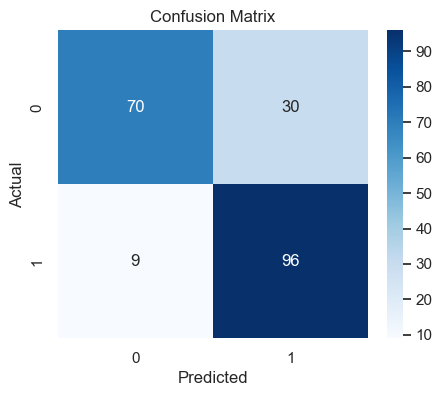

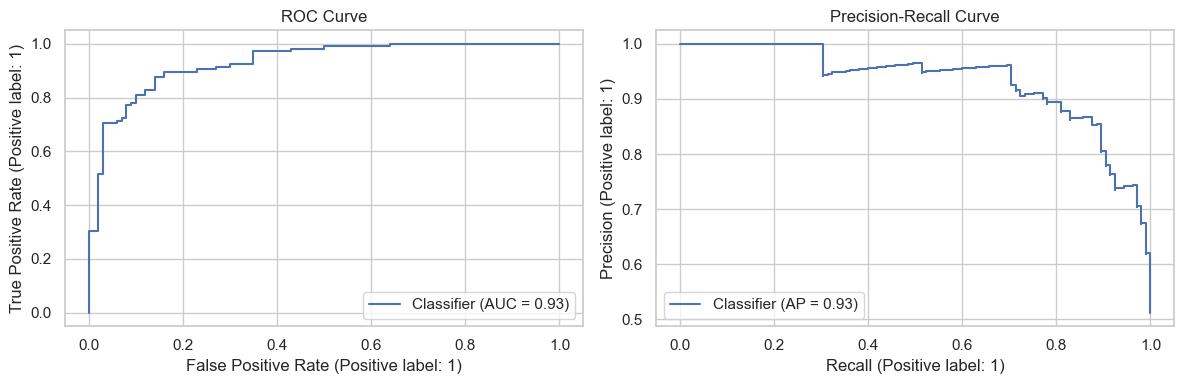

In [37]:
# Evaluate on hold-out test set
y_pred = log_reg_pipe.predict(X_test)
y_proba = log_reg_pipe.predict_proba(X_test)[:, 1]

metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1_score': f1_score(y_test, y_pred),
    'roc_auc': roc_auc_score(y_test, y_proba),
}

display(pd.DataFrame(metrics, index=['Logistic Regression']).T)

print('Classification report:')
print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0])
axes[0].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title('Precision-Recall Curve')
plt.tight_layout()
plt.show()


### Save Model Artifacts

Export trained artifacts for app deployment and later reuse.

In [38]:
# Save trained model artifacts for deployment/reuse
ARTIFACT_DIR = Path('model_artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)

joblib.dump(log_reg_pipe.named_steps['model'], ARTIFACT_DIR / 'model.pkl')
joblib.dump(log_reg_pipe.named_steps['scaler'], ARTIFACT_DIR / 'scaler.pkl')

metadata = {
    'n_rows': int(df.shape[0]),
    'n_features': int(len(feature_cols)),
    'feature_order': feature_cols,
    'random_state': RANDOM_STATE,
    'cv_roc_auc_mean': float(cv_auc.mean()),
    'cv_roc_auc_std': float(cv_auc.std()),
    'cv_f1_mean': float(cv_f1.mean()),
    'cv_f1_std': float(cv_f1.std()),
    'test_metrics': {k: float(v) for k, v in metrics.items()}
}
(ARTIFACT_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

print('Saved artifacts to model_artifacts/: model.pkl, scaler.pkl, metadata.json')

Saved artifacts to model_artifacts/: model.pkl, scaler.pkl, metadata.json


### Coefficients and odds ratios

Extracting coefficients and odds ratios to interpret how each feature influences predicted heart disease risk.

,feature,coefficient,odds_ratio
2,cp,0.864490,2.373794
1,sex,-0.788251,0.454639
11,ca,-0.750849,0.471966
9,oldpeak,-0.607841,0.544525
8,exang,-0.514387,0.597867
12,thal,-0.498568,0.607400
7,thalach,0.418924,1.520326
10,slope,0.368408,1.445432
3,trestbps,-0.363981,0.694905
4,chol,-0.280492,0.755412


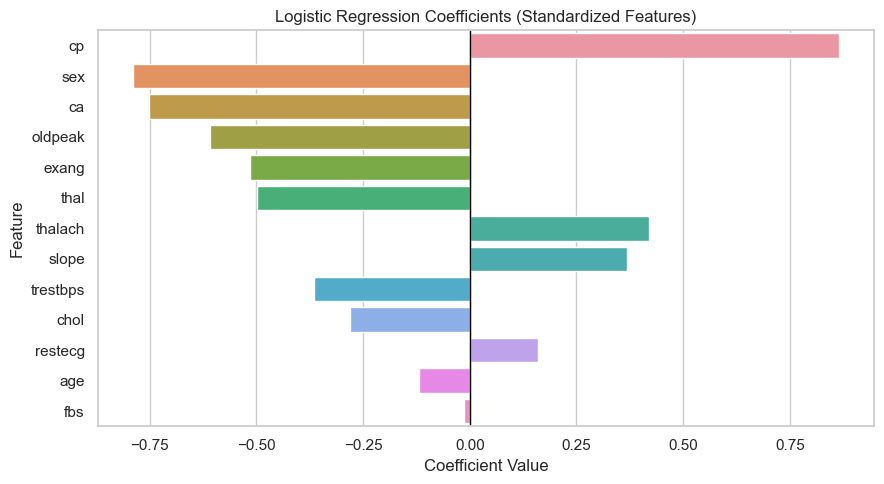

In [39]:
# Interpretability: feature coefficients and odds ratios
model = log_reg_pipe.named_steps['model']
coefs = model.coef_[0]
odds_ratios = np.exp(coefs)

coef_df = pd.DataFrame({
    'feature': feature_cols,
    'coefficient': coefs,
    'odds_ratio': odds_ratios,
    'abs_coefficient': np.abs(coefs)
}).sort_values('abs_coefficient', ascending=False)

display(coef_df[['feature', 'coefficient', 'odds_ratio']])

plt.figure(figsize=(9, 5))
sns.barplot(data=coef_df, x='coefficient', y='feature', orient='h')
plt.axvline(0, color='black', linewidth=1)
plt.title('Logistic Regression Coefficients (Standardized Features)')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


### Model Testing

I run a single-patient inference example to demonstrate how the trained model is used for prediction.

In [40]:
# Example single-patient prediction (replace values as needed)
example_patient = {
    'age': 62, 'sex': 1, 'cp': 2, 'trestbps': 150, 'chol': 320,
    'fbs': 0, 'restecg': 1, 'thalach': 110, 'exang': 1,
    'oldpeak': 2.8, 'slope': 1, 'ca': 2, 'thal': 7
}

example_df = pd.DataFrame([example_patient])
example_prob = log_reg_pipe.predict_proba(example_df)[0, 1]
example_pred = int(example_prob >= 0.5)

print('Prediction:', 'Heart Disease Present' if example_pred == 1 else 'Heart Disease Absent')
print(f'Probability of heart disease: {example_prob:.3f}')


Prediction: Heart Disease Absent
Probability of heart disease: 0.000
